In [19]:
from dotenv import load_dotenv
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import utils.AmexMetrics as AmexMetrics
from models.TabTransformer import run_experiment as run_experiment_c, infer_tabtransformer as infer_tabtransformer_c
from models.qCLSTabTransformer import run_experiment as run_experiment_q, infer_tabtransformer as infer_tabtransformer_q
from utils.Preprocessor import preprocess_amex

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
#Use .env file with Kaggle API Token to download AMEX dataset
load_dotenv()
os.environ["KAGGLE_API_TOKEN"] = os.getenv("KAGGLE_API_TOKEN")
path = kagglehub.competition_download("amex-default-prediction")
file = os.path.join(path, "train_data.csv")
data_all = pd.read_csv(file, nrows=1e6)
file = os.path.join(path, "train_labels.csv")
labels_all = pd.read_csv(file,nrows=1e6)

In [29]:
def get_metrics(targets, probs):
    y_true_c = pd.DataFrame({"target": targets})
    y_pred_c = pd.DataFrame({"prediction": probs})
    M_c = AmexMetrics.amex_metric(y_true_c, y_pred_c)
    g_c = AmexMetrics.normalized_weighted_gini(y_true_c, y_pred_c)
    d_c = AmexMetrics.top_four_percent_captured(y_true_c, y_pred_c)
    return M_c, g_c, d_c

def run_statistical_analysis(num_seeds, qufex_params, entangling=True):
    Ms_c_2000 = []
    Ms_q_2000 = []
    gs_c_2000 = []
    gs_q_2000 = []
    ds_c_2000 = []
    ds_q_2000 = []

    Ms_c_6000 = []
    Ms_q_6000 = []
    gs_c_6000 = []
    gs_q_6000 = []
    ds_c_6000 = []
    ds_q_6000 = []

    for seed in range(num_seeds):
        #Scrape all data associated with the a random n customers
        customers = data_all["customer_ID"].drop_duplicates().sample(n=12000, random_state=seed)
        data_without_labels = data_all[data_all["customer_ID"].isin(customers)]
        labels = labels_all[labels_all["customer_ID"].isin(customers)]
        data = preprocess_amex(data_without_labels, labels)
        frac_fraud = np.sum(data['Class'])/len(data['Class'])

        fraud_data = data[data['Class'] == 1].sample(frac=1, random_state=42)
        non_fraud_data = data[data['Class'] == 0].sample(frac=1, random_state=42)

        train_size = 2000
        training_fraud = int(frac_fraud*train_size) #Use for AMEX
        data_subset = pd.concat([fraud_data[:training_fraud], non_fraud_data[:train_size - training_fraud]]).sample(frac=1, random_state=42) #Use for AMEX

        #Run classical experiment on small dataset
        model_c, test_results_c, test_df = run_experiment_c(data_subset, lr=1e-3)
        print(f'Classical model test Amex metric: {test_results_c["amex_metric"]}, Seed={seed}')

        #Run quantum experiment on small dataset
        model_q, test_results_q, test_df = run_experiment_q(data_subset, lr=7e-4, qufex_params=qufex_params, entangling=entangling)
        print(f'Quantum CLS model test Amex metric: {test_results_q["amex_metric"]}, Seed={seed}, QuFeX{qufex_params}\n')


        #Gathers metrics for different inference sizes to see how well the models generalize
        inference_sizes = [2000, 6000]
        inference_fraud = int(frac_fraud * np.max(inference_sizes))
        inference_df = pd.concat([fraud_data[training_fraud:training_fraud + inference_fraud],
                                    non_fraud_data[train_size - training_fraud:train_size - training_fraud + np.max(inference_sizes) - inference_fraud]]
                                    ).sample(frac=1, random_state=42)

        #Classical model inference
        results = infer_tabtransformer_c(model_c, inference_df)
        probs_c_all = results['probs']
        targets_c_all = results['targets']

        #Quantum model inference
        results = infer_tabtransformer_q(model_q, inference_df)
        probs_q_all = results['probs']
        targets_q_all = results['targets']

        #Calculates inference metrics by size grouping to visualize scaling
        size = 2000

        M, g, d = get_metrics(targets_c_all[:size], probs_c_all[:size])
        gs_c_2000.append(g)
        ds_c_2000.append(d)
        Ms_c_2000.append(M)

        M, g, d = get_metrics(targets_q_all[:size], probs_q_all[:size])
        gs_q_2000.append(g)
        ds_q_2000.append(d)
        Ms_q_2000.append(M)

        #Calculates inference metrics by size grouping to visualize scaling
        size = 6000

        M, g, d = get_metrics(targets_c_all[:size], probs_c_all[:size])
        gs_c_6000.append(g)
        ds_c_6000.append(d)
        Ms_c_6000.append(M)

        M, g, d = get_metrics(targets_q_all[:size], probs_q_all[:size])
        gs_q_6000.append(g)
        ds_q_6000.append(d)
        Ms_q_6000.append(M)

    metrics = [Ms_c_2000, 
        gs_c_2000, 
        ds_c_2000, 
        Ms_q_2000,
        gs_q_2000,
        ds_q_2000,
        Ms_c_6000,
        gs_c_6000,
        ds_c_6000,
        Ms_q_6000,
        gs_q_6000,
        ds_q_6000,
    ]

    return metrics

In [ ]:
def plot_M(metrics, num_seeds, quantum_label):
    M_means_c = [np.mean(metrics[0]), np.mean(metrics[6])]
    M_ses_c = [np.std(metrics[0], ddof=1)/np.sqrt(num_seeds), np.std(metrics[6], ddof=1)/np.sqrt(num_seeds)]
    M_means_q = [np.mean(metrics[3]), np.mean(metrics[9])]
    M_ses_q = [np.std(metrics[3], ddof=1)/np.sqrt(num_seeds), np.std(metrics[9], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, M_means_c, yerr=M_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, M_means_q, yerr=M_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('AmEx Proposed Metric')
    plt.title('Inference for AmEx Default Prediction on 30k param models')
    plt.legend()
    plt.show()

def plot_G(metrics, num_seeds, quantum_label):
    G_means_c = [np.mean(metrics[1]), np.mean(metrics[7])]
    G_ses_c = [np.std(metrics[1], ddof=1)/np.sqrt(num_seeds), np.std(metrics[7], ddof=1)/np.sqrt(num_seeds)]
    G_means_q = [np.mean(metrics[4]), np.mean(metrics[10])]
    G_ses_q = [np.std(metrics[4], ddof=1)/np.sqrt(num_seeds), np.std(metrics[10], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, G_means_c, yerr=G_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, G_means_q, yerr=G_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('G')
    plt.title('Inference Normalized Gini Coefficient for 30k param models')
    plt.legend()
    plt.show()

def plot_D(metrics, num_seeds, quantum_label):
    D_means_c = [np.mean(metrics[2]), np.mean(metrics[8])]
    D_ses_c = [np.std(metrics[2], ddof=1)/np.sqrt(num_seeds), np.std(metrics[8], ddof=1)/np.sqrt(num_seeds)]
    D_means_q = [np.mean(metrics[5]), np.mean(metrics[11])]
    D_ses_q = [np.std(metrics[5], ddof=1)/np.sqrt(num_seeds), np.std(metrics[11], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, D_means_c, yerr=D_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, D_means_q, yerr=D_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('D')
    plt.title('Inference Default Rate at 4% for 30k param models')
    plt.legend()
    plt.show()

In [ ]:
num_seeds = 10
metrics_411 = run_statistical_analysis(num_seeds, (4,1,1))
np.save("411baseline", metrics_411)
metrics_422 = run_statistical_analysis(num_seeds, (4,2,2))
np.save("422baseline", metrics_422)
metrics_612 = run_statistical_analysis(num_seeds, (6,1,2))
np.save("612baseline", metrics_612)
metrics_422_unentangled = run_statistical_analysis(num_seeds, (4,2,2), entangling=False)
np.save("422unentangled", metrics_422_unentangled)

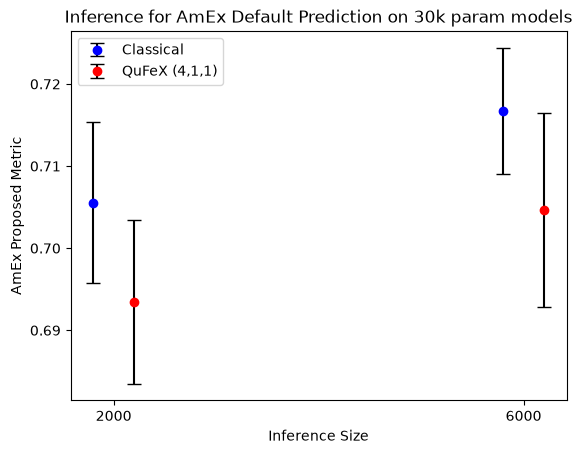

In [36]:
metrics_411 = np.load("../metrics/411baseline.npy")
plot_M(metrics_411, num_seeds=10, quantum_label="QuFeX (4,1,1)")
#plot_G(metrics_411, num_seeds=10, quantum_label="QuFeX (4,1,1)")
#plot_D(metrics_411, num_seeds=10, quantum_label="QuFeX (4,1,1)")

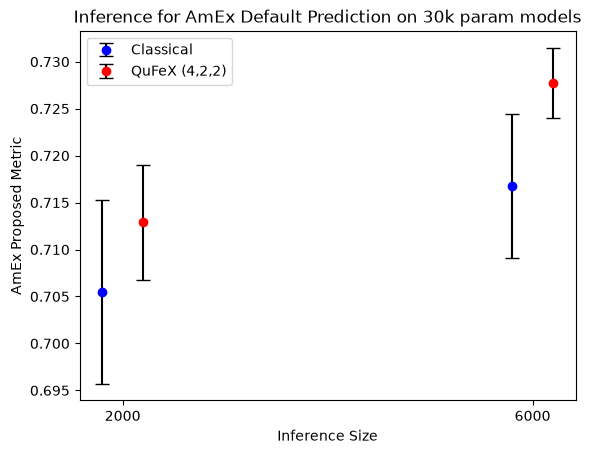

In [37]:
metrics_422 = np.load("../metrics/422baseline.npy")
plot_M(metrics_422, num_seeds=10, quantum_label="QuFeX (4,2,2)")
#plot_G(metrics_422, num_seeds=10, quantum_label="QuFeX (4,2,2)")
#plot_D(metrics_422, num_seeds=10, quantum_label="QuFeX (4,2,2)")

In [ ]:
metrics_612 = np.load("../metrics/612baseline.npy")
plot_M(metrics_612, num_seeds=10, quantum_label="QuFeX (6,1,2)")
#plot_G(metrics_612, num_seeds=10, quantum_label="QuFeX (6,1,2)")
#plot_D(metrics_612, num_seeds=10, quantum_label="QuFeX (6,1,2)")

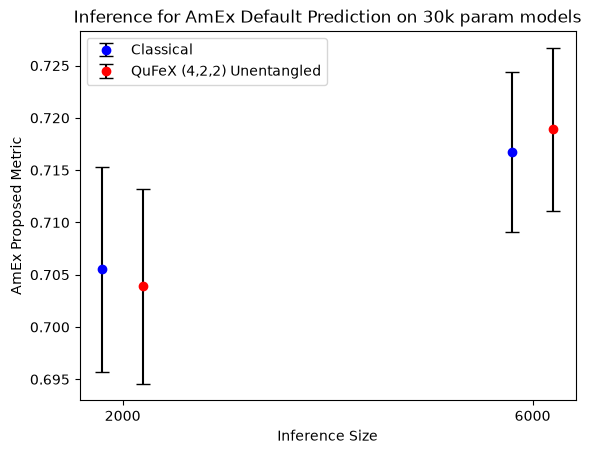

In [38]:
metrics_422_unentangled = np.load("../metrics/422unentangled.npy")
plot_M(metrics_422_unentangled, num_seeds=10, quantum_label="QuFeX (4,2,2) Unentangled")
#plot_G(metrics_422_unentangled, num_seeds=10, quantum_label="QuFeX (4,2,2) Unentangled")
#plot_D(metrics_422_unentangled, num_seeds=10, quantum_label="QuFeX (4,2,2) Unentangled")